# Qiskit-Metal-to-Litho six-Xmon chip: a Quantcore-PDK rebuild, step by step

**Source:** Onri Jay Benally (OJB-Quantum), **Qiskit-Metal-to-Litho**,
`6_Xmon_Layout_with_Quantum_Metal_PHIDL_GDSTK_in_Colab.ipynb`, <https://github.com/OJB-Quantum/Qiskit-Metal-to-Litho>,
licence **CC BY 4.0** (`LICENSE`; attribution: © Onri Jay Benally, adapted). The notebook's design constants were
read on 2026-11-03 (never executed). Spec: `docs/designs/community/qm2litho_6xmon.md`.

**What the chip is:** six Metal `TransmonCross` qubits in two columns of three, one column on each side of a straight
vertical feedline (11.7/5.1 µm) between two `LaunchpadWirebond`s. Each qubit has a claw toward the line and a λ/4
meander readout coupled through a `CoupledLineTee` (200 µm coupled, 4 µm ground strip, shorted, 110 µm down leg).
Readout targets 6.116–6.704 GHz come from L = v / (4 f) with v = 1.2 × 10⁸ m/s. The cross and L_J (15.904 nH) are those
of the SQuADDS tutorial-5 qubit. A second section of the source notebook writes a **cheesed variant** of the same
chip: an antidot (vortex-trap) field of 2 µm squares on a 10 µm pitch, 15 µm from the metal (45 µm round the pads).

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source (Qiskit-Metal-to-Litho) | this rebuild |
|---|---|---|
| die and frame | Metal's 5 × 5 mm chip centred on (0, 0), no frame; the pads overhang it by 83 µm | PDK 5 × 5 mm die (Designer = source + (2500, 2500) µm): dicing L's, alignment grids, device ID `QM2L-6X` |
| stack | silicon (Metal default) | PDK sapphire 650 µm, εr 10.25 |
| qubits, launchpads | Metal `TransmonCross`, `LaunchpadWirebond` | the same cells and options through the `metal:` wrappers |
| junction | lumped L_J 15.904 nH (`hfss_inductance`) | Quantcore Nb trilayer junction drawn for L_J = 15.904 nH (`trilayer_junction`); R_n is flagged, not retuned |
| readout coupler | `CoupledLineTee` + `RouteMeander` | one qcc λ/4 hanger route per qubit: claw → meander → 200 µm coupled section (4 µm strip) → short |
| launchpads | at y ±2100 µm, overhanging the chip | **PDK pad rule**: outer etch `frame.pad_edge` = 100 µm inside the north / south die edges |
| cheese | the cheesed variant: 2 µm antidots, 10 µm pitch, 15 µm clearance | **the original's cheese**: the same antidot field as the chip's `cheese` rule, drawn by the build and kept in the mask; no PDK band |
| netlist, LOM, FEM jobs | none | our netlist, LOM and Q3D / eigenmode job exports per qubit |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the die with the source's antidot cheese, the two launchpads, the feedline, the six Xmons with
their trilayer junctions, their six λ/4 hanger readouts, and then the whole chip (the sim groups and targets, the
centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `qm2litho_6xmon.v1.ipynb`; both save the same
`qm2litho_6xmon.json`.

## Setup

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with `QCC_LIVE=0` (tests,
batch runs) the snapshots are rendered headless.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on. Every rule is applied by the library, not by this notebook: the frame and the cheese by
the chip build, the pad rule by `edge=`, the junction by `trilayer_junction`, the design warnings by the DRC.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so the feedline is drawn as soon as
both pads exist (segment 3) and each readout once its qubit is there (segment 5). Every position is a source
coordinate + (2500, 2500) µm, so the order changes nothing.

| segment | what is placed here |
|---|---|
| 1 | the 5 × 5 mm die with the PDK frame and the source's antidot field as the chip's cheese rule |
| 2 | the two launchpads, north and south, on the PDK pad rule |
| 3 | the readout line: the straight 11.7/5.1 µm feedline between them |
| 4 | the six `TransmonCross` Xmons (two columns of three) with their trilayer junctions |
| 5 | the six λ/4 hanger readouts, claw → meander → coupled section → short |
| 6 | the coupling: none (the qubits are not coupled to each other) |
| 7 | the control routing: none (the source draws no drive or flux line) |
| 8 | the whole chip: the sim groups and targets, the centring, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the source's 5 × 5 mm chip, so Designer = source +
(2500, 2500) µm. The PDK draws the frame round it: L dicing markers (1000/0), 3 × 3 alignment grids (1001/0), the chip
boundary (100/0) and the device ID (`name_chip`) on a free edge.

**Cheese: the original's.** The source's cheesed variant has an antidot (vortex-trap) field: 2 µm squares on a 10 µm
pitch, 15 µm from the metal. The original wins, so the chip carries that field as its `cheese` rule (`size`, `gap`,
`rows`, `clearance`) and the build draws it instead of the PDK band (layout, snapshots, KLive and the mask). The rule's
`clearance` is measured from the 3/0 keep-out, which already adds the PDK route margin (10 µm) round each CPW, so
15 − 10 = 5 µm keeps the holes 15 µm from the line etch, as in the source (and further from the components, whose
keep-out margin is larger). `rows` 1000 fills the whole free ground. The source's wider 45 µm round the pads is not
reproduced (one clearance for everything).

chip cheese rule: {'size': 2.0, 'gap': 8.0, 'rows': 1000, 'clearance': 5.0}


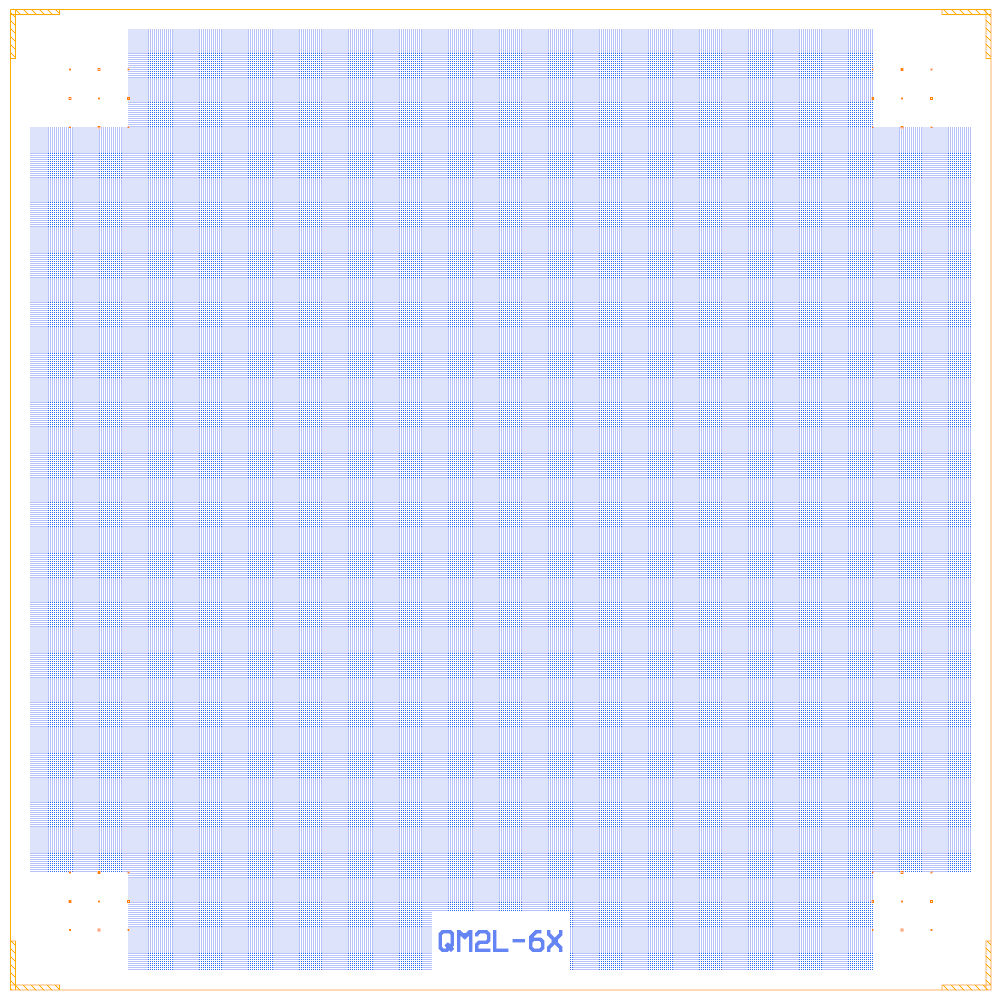

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/qm2litho_6xmon_die.png')

In [5]:
from quantcore_circuits.pdk import get_pdk

X0, Y0 = 2500, 2500                              # Metal's 5 × 5 mm chip is centred on (0, 0)
ANTIDOTS = {"size": 2.0, "gap": 8.0, "rows": 1000,  # the source's field: 2 µm squares on a 10 µm pitch,
            "clearance": 15.0 - get_pdk().keepout.route_margin}   # 15 µm from the CPW etch (3/0 adds 10 µm)
d = Designer("qm2litho_6xmon", box=(0, 0, 5000, 5000),
             chip={"name_chip": "QM2L-6X", "cheese": ANTIDOTS}, live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
layout_step(d, OUT / "qm2litho_6xmon_die.png", size=(1000, 1000), width=360)

## Design 2 · Bond pads: the two launchpads and the PDK pad rule

The source puts its two `LaunchpadWirebond`s (160 × 200 µm pad, 58 µm gap, 200 µm taper, 25 µm lead, 11.7/5.1 µm trace)
at y = ±2100 µm, where they overhang Metal's 5 mm chip by 83 µm. The PDK puts every bond pad and launcher with the outer
edge of its etch **`frame.pad_edge` = 100 µm from the die edge**: `edge="n"` / `edge="s"` slides each pad
perpendicular to that edge until it holds, keeping its x. `pads_md(d)` lists the distances.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| WB_TOP | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| WB_BOT | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

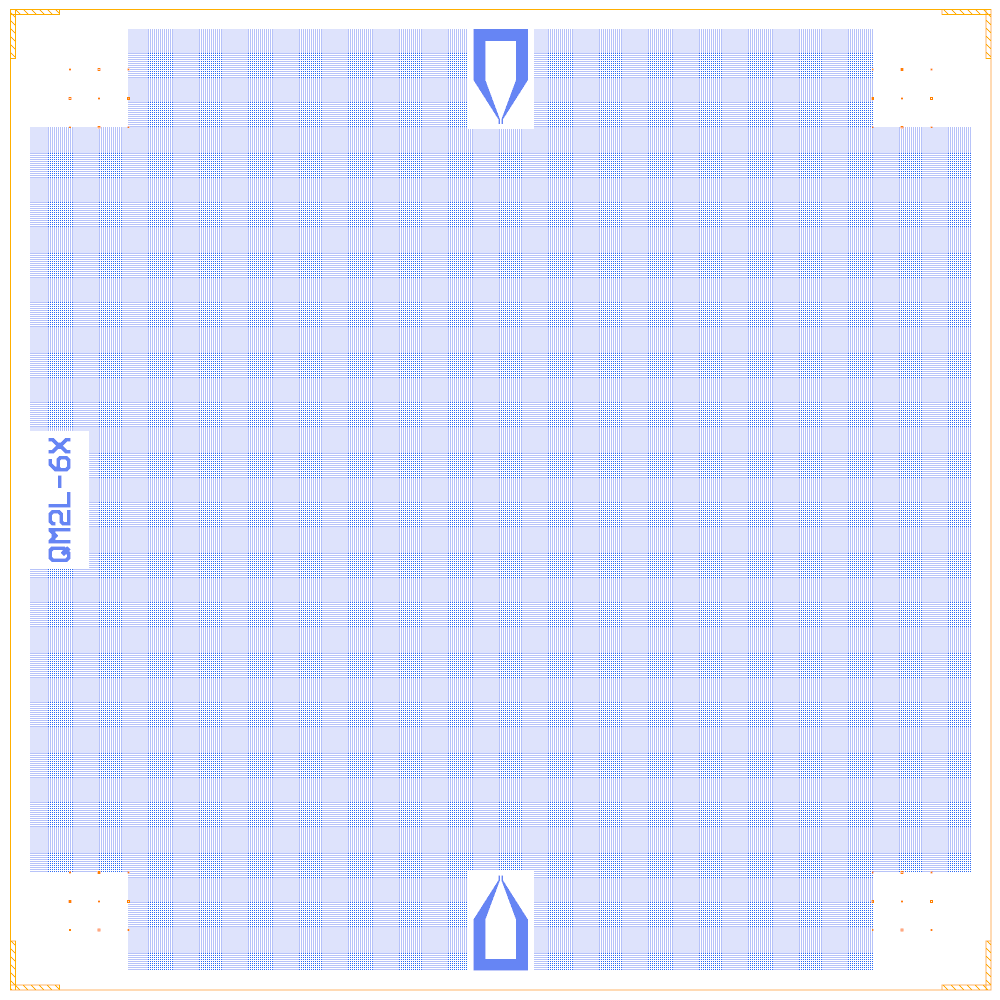

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `WB_TOP`, `WB_BOT`.

WindowsPath('examples/designs/community/qm2litho_6xmon_s2_pads.png')

In [6]:
PAD = dict(trace_width=11.7, trace_gap=5.1, lead_length=25, pad_width=160, pad_height=200, pad_gap=58, taper_height=200)
top = d.add("WB_TOP", "metal:LaunchpadWirebond", at=(X0, Y0 + 2100), rot=-90, edge="n", **PAD)
bot = d.add("WB_BOT", "metal:LaunchpadWirebond", at=(X0, Y0 - 2100), rot=90, edge="s", **PAD)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "qm2litho_6xmon_s2_pads.png", size=(1000, 1000), width=360)

## Design 3 · Readout: the feedline

**The feedline** is a straight 11.7/5.1 µm CPW from the top pad's `tie` to the bottom pad's `tie`. It travels −y, so
its "right" side is the west column and its "left" side the east column. It needs no qubit, so it comes first; every
readout will hang on it (Design 5).

FL: 3834.0 µm


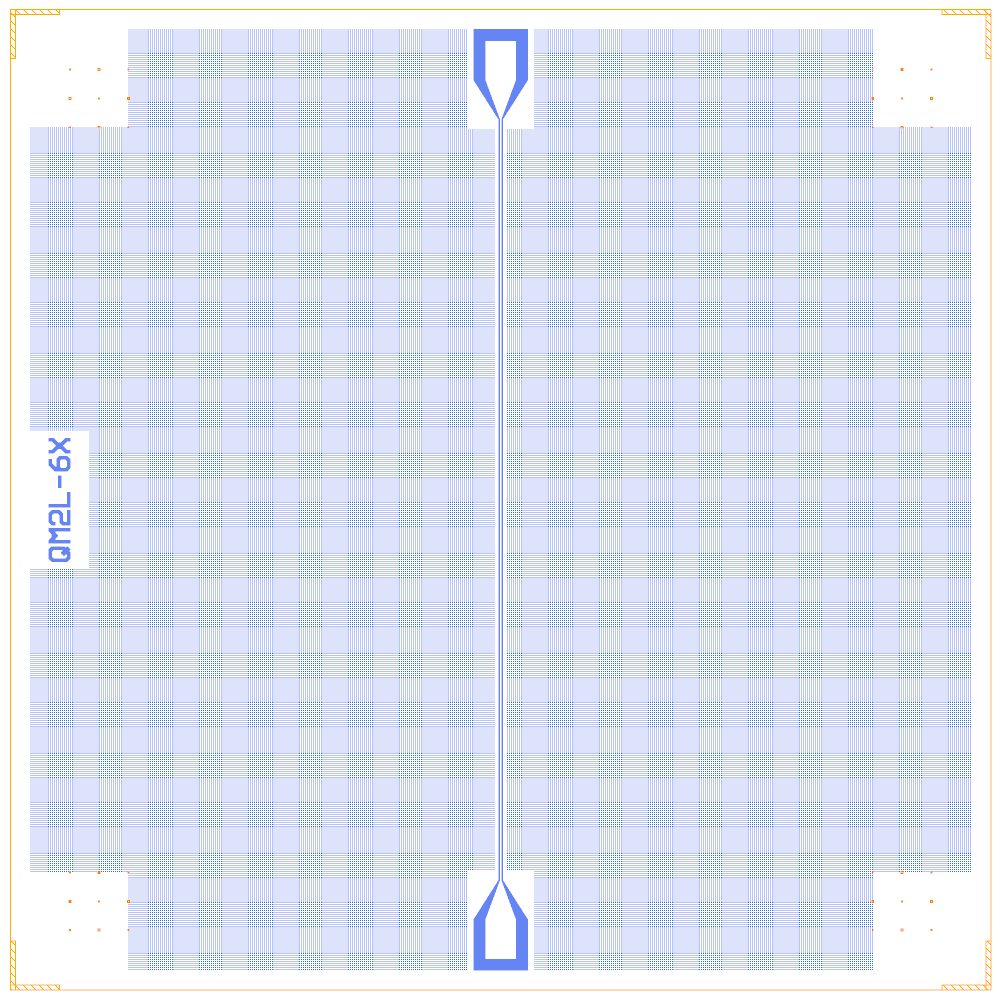

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `FL`.

WindowsPath('examples/designs/community/qm2litho_6xmon_s3_feedline.png')

In [7]:
fl = d.route("FL", top.tie, bot.tie, a=11.7, b=5.1)
rebuild(d)
print(f"FL: {fl.length:.1f} µm")
layout_step(d, OUT / "qm2litho_6xmon_s3_feedline.png", size=(1000, 1000), width=360)

## Design 4 · Qubit placement: six Xmons with trilayer junctions

**The junction.** The source gives L_J = 15.904 nH (its `hfss_inductance`). `trilayer_junction(cell, lj_nH=...)`
returns the cell parameters that draw a Quantcore Nb/AlOx/Nb trilayer junction sized for it on the PDK junction rule
(fingers on 2/0 and 4/0, spacer 50/0 with the 51–53/0 gradient) and the values the LOM uses. At 15.9 nH the junction
is small (the PDK finger grid draws 16.03 nH): R_n 107 kΩ, **outside the PDK window of 40–50 kΩ**. Following the project rule (values are flagged, never
retuned), the source's L_J stays and the DRC reports the design warning `pdk_rn`.

In [8]:
LJ_NH = 15.903982                                # the source's Lj (SQuADDS tutorial-5 qubit)
JJP, JJ = trilayer_junction("metal:TransmonCross", lj_nH=LJ_NH)
print("cell parameters:", JJP)
print("LOM junction:   ", JJ, f"→ R_n {rn_from_lj(JJ['Lj_nH']) / 1e3:.1f} kΩ (PDK window 40–50 kΩ)")

cell parameters: {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 15.903982}}
LOM junction:    {'Lj_nH': 16.0343, 'Cj_fF': 6.3} → R_n 107.1 kΩ (PDK window 40–50 kΩ)


**The qubits.** Metal `TransmonCross`: cross 260 µm arms, 35 µm wide, 20 µm gap, with one claw (190 × 10 µm, 6 µm gap,
5 µm ground spacing, 60 µm claw CPW) on the arm facing the line (`connector_location="90"`). The west column is
rotated −90° and the east column +90°, so every claw faces the feedline; `q.c` is the claw's pin.

<metal:TransmonCross Q1_L ports=['c', 'squid_a', 'squid_b']>

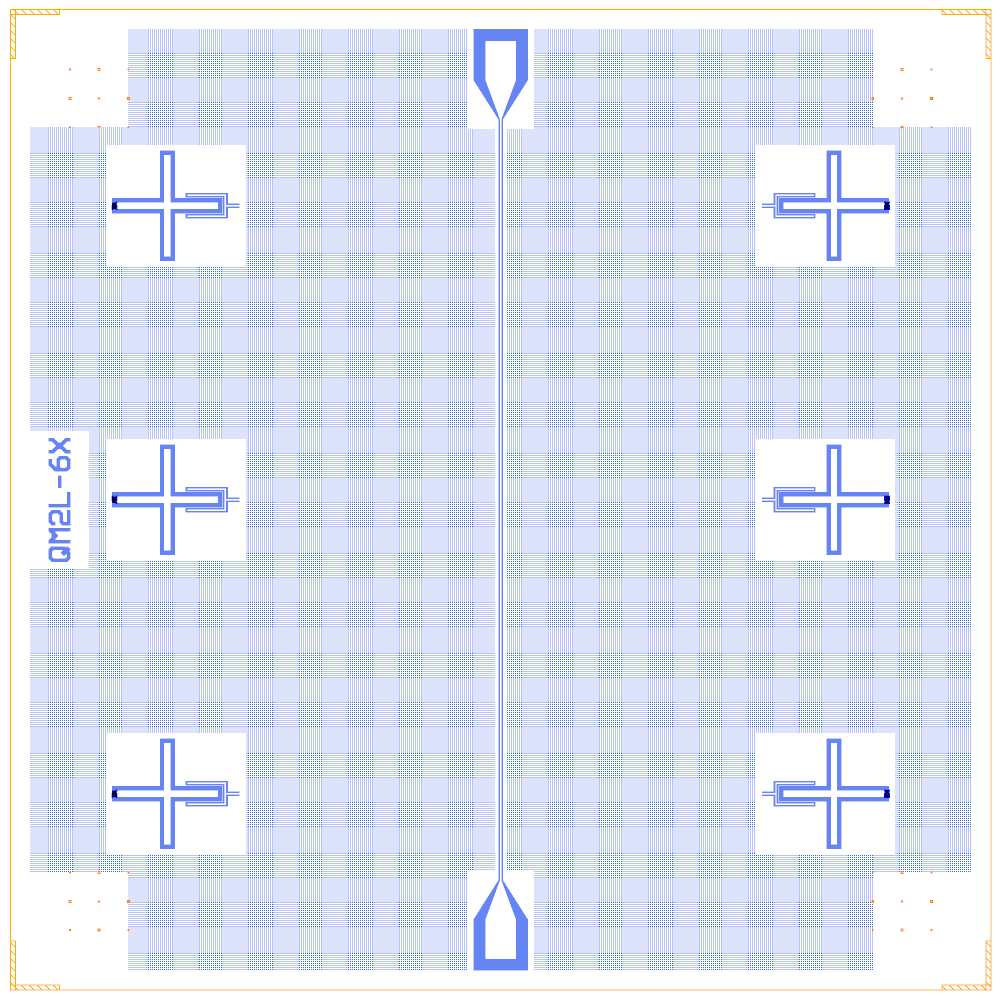

**On the chip so far:** 2 pads · 6 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 6 component(s) `Q1_L`, `Q2_L`, `Q3_L`, `Q1_R`, `Q2_R`, `Q3_R`.

WindowsPath('examples/designs/community/qm2litho_6xmon_components.png')

In [9]:
CLAW = dict(connector_location="90", connector_type="0", claw_length=190, claw_gap=6, claw_width=10,
            claw_cpw_length=60, claw_cpw_width=10, ground_spacing=5)
CROSS = dict(cross_length=260, cross_width=35, cross_gap=20, connection_pads={"c": CLAW})
SITES = (("Q1_L", -1700, 1500), ("Q2_L", -1700, 0), ("Q3_L", -1700, -1500),
         ("Q1_R", 1700, 1500), ("Q2_R", 1700, 0), ("Q3_R", 1700, -1500))   # source (x, y), µm
qubits = {}
with d.batch():
    for name, x, y in SITES:
        qubits[name] = d.add(name, "metal:TransmonCross", at=(X0 + x, Y0 + y), rot=-90 if x < 0 else 90,
                             junction=JJ, **CROSS, **JJP)
print(qubits["Q1_L"])
layout_step(d, OUT / "qm2litho_6xmon_components.png", size=(1000, 1000), width=360)

## Design 5 · Readout: six λ/4 hanger readouts

Each source readout is a `RouteMeander` from the claw to a `CoupledLineTee` on the feedline. In the rebuild it is one
qcc route: claw → meander → a 200 µm section running along the feedline with a 4 µm ground strip → short to ground.
- `fl.hanger(near=(x, y), length=200, side=..., ground_gap=4, end="short")` centres the coupled section at the
  feedline point nearest (x, y); here 100 µm below each qubit's centre, as in the source. Placing it by position
  (`near=`) and not by arclength along the feedline keeps it in place when the pads move.
- `meander=L` fixes the total length: the source's meander L = v / (4 f) **plus the tee's own 200 µm coupled section and
  110 µm down leg** (310 µm), which are part of the physical λ/4. The resonators therefore come out below the source's
  targets, which ignore the tee.
- 5 meanders, 70 µm bends (the source's fillet): the router draws the length the path leaves over as one KQC
  `Meander` with the 5 turns asked for (fewer, with a warning, only if 5 would be narrower than the bend radius).

The sim groups and the readout targets are set in Design 8, with the whole chip.

{'FL': 3834.0, 'R_Q1_L': 5215.2, 'R_Q2_L': 5032.2, 'R_Q3_L': 4945.4, 'R_Q1_R': 4877.6, 'R_Q2_R': 4817.9, 'R_Q3_R': 4784.9}


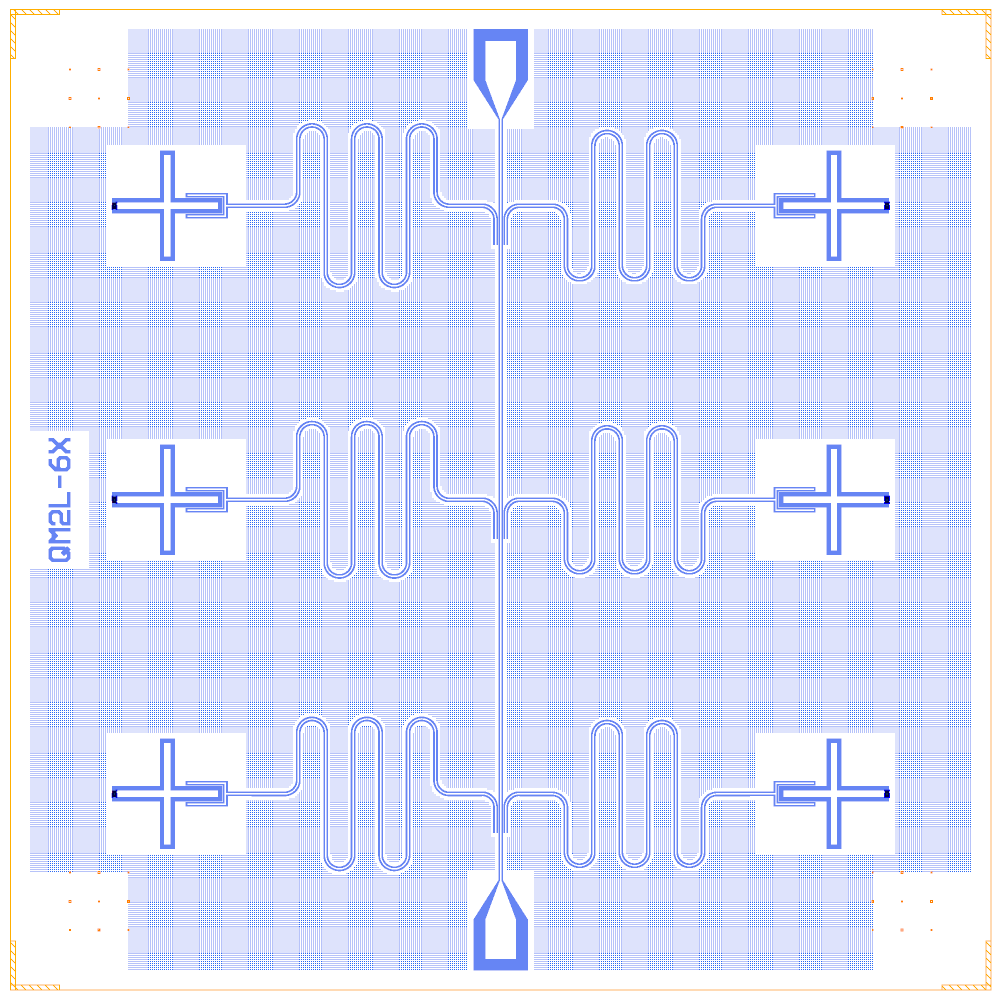

**On the chip so far:** 2 pads · 6 qubits · 0 other components · 7 routes · 0 declared couplings. **This step added** 6 route(s) `R_Q1_L`, `R_Q2_L`, `R_Q3_L`, `R_Q1_R`, `R_Q2_R`, `R_Q3_R`.

WindowsPath('examples/designs/community/qm2litho_6xmon_s5_readouts.png')

In [10]:
F_GHZ = (6.116, 6.353, 6.472, 6.568, 6.655, 6.704)  # source targets, in site order
CLT_LINE = 200 + 110                             # the tee's coupled section + down leg (part of the λ/4)
with d.batch():
    for (name, x, y), f in zip(SITES, F_GHZ):
        L_src = 1.20e8 / (4 * f * 1e9) * 1e6     # source meander length (µm)
        hg = fl.hanger(near=(X0, Y0 + y - 100), length=200, side="right" if x < 0 else "left", ground_gap=4,
                       direction="forward", end="short")
        d.route(f"R_{name}", qubits[name].c, hg, meander=round(L_src + CLT_LINE, 1), r=70).set(meanders=5)
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "qm2litho_6xmon_s5_readouts.png", size=(1000, 1000), width=360)

## Design 6 · Coupling: none

The six qubits are not coupled to each other (no bus, no coupler): each sees only its readout and, through it, the
feedline. Nothing is placed here.

## Design 7 · Routing: no control lines

The source draws no drive or flux line: the cross's claw is each qubit's only connection. Nothing is routed here.

## Design 8 · The whole chip: sim groups, targets, centring, save

**Sim groups and targets:** one sim group per qubit with its readout and the feedline
(the default analyses: eigenmode / EPR and Q3D C-matrix), and each readout's target, the source's f = v / (4 L).

**Centring.** The source chip is symmetric about its centre and the rebuild keeps the source coordinates, so the content is already
centred: `center_in_die(d)` measures the bounding box of every instance and route and returns (0, 0) when it is
within 50 µm of the die centre (it would shift everything otherwise).

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's, the `.v1` notebook's): the segments above changed how the chip is built, not the chip, so it should say
*same design*. The file keeps the previous key order (here every instance, route, sim group and target comes in the v1's order anyway), so `git diff` stays empty.

shift applied (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/community/qm2litho_6xmon.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer qm2litho_6xmon: 8 instances, 7 routes, live=False> → examples\designs\community\qm2litho_6xmon.json


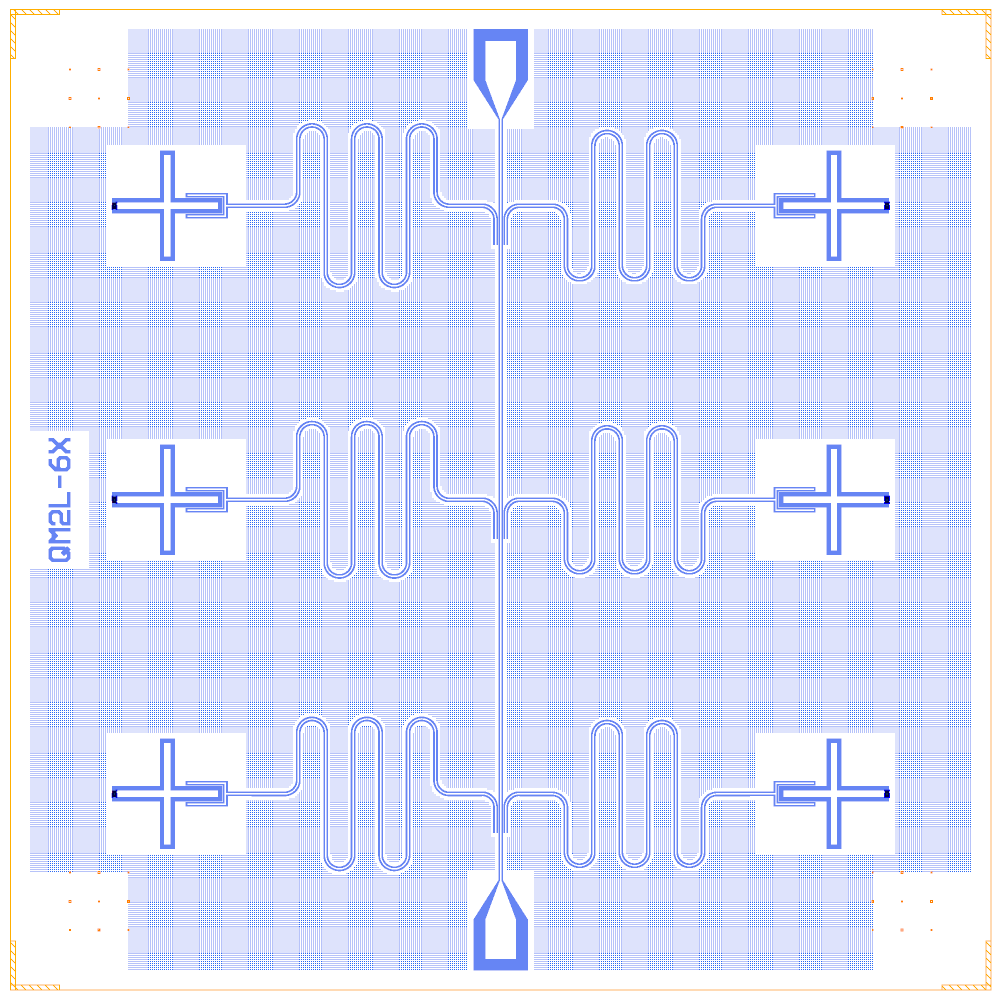

**On the chip so far:** 2 pads · 6 qubits · 0 other components · 7 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/qm2litho_6xmon_routes.png')

In [11]:
for (name, x, y), f in zip(SITES, F_GHZ):
    d.sim_group(name, [name, f"R_{name}", "FL"])
    d.targets(**{f"R_{name}": {"f_GHz": f}})
print("shift applied (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "qm2litho_6xmon.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "qm2litho_6xmon_routes.png", size=(1000, 1000), width=360)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK margins:
- **errors** would make the chip wrong; there must be none;
- **warnings** are worth a look but can be intended: here the `TransmonCross` junction attachment points
  (`squid_a` / `squid_b`; the cell draws its own junction), not route ends;
- **PDK design warnings** flag values outside the PDK margins (`pdk_rn`, `pdk_fq`, `pad_edge`, `pdk_claw`); they are
  reported, never enforced. Here: `pdk_rn` on all six qubits (the source's 15.9 nH).

Expected (from the v1 run): **no errors**; 12 `dangling_port` warnings, the six crosses' `squid_a` / `squid_b`; 6 `pdk_rn`
(R_n 107.1 kΩ). No `pad_edge`: both launchpads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit. Each grounded `TransmonCross` is an island node with its junction to
ground and a claw node coupled to it; each readout is a λ/4 `TLres` from the claw node, with a `HANGER` (κ) to the
feedline node `FL`, which carries the two 50 Ω launchpad ports.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation (per qubit / readout pair, with the feedline)

Each qubit is simulated with its readout and the feedline (QuCat normal modes, then the QuTiP dressed values). Targets
in brackets are the source's L = v/(4f) values for the meander alone; the rebuild's λ/4 also includes the tee's 310 µm,
so f_r sits lower. The source states no qubit frequency (≈ 3.7 GHz if it matches the SQuADDS entry); the design sets no qubit
target, so the DRC has no `pdk_fq` warning to give.

What the table shows (from the v1 run):
- every qubit at **3.183 GHz** (α −151 MHz) with the drawn trilayer junction (L_J 16.03 nH, C_J 6.3 fF instead of the
  source's assumed 2 fF): below the PDK band of 4–8 GHz; LOM 3 shows what the PDK nominal junction would do;
- the readouts at **5.431 … 5.869 GHz**, 0.69–0.84 GHz (11–12 %) below the source's 6.116 … 6.704 GHz: the tee's
  310 µm (≈ 6 % of each λ/4) is in our length, the claw loads the open end and the PDK CPW on sapphire is slower than
  the source's v = 1.2 × 10⁸ m/s. Flagged, not retuned;
- κ 0.060–0.075 MHz through the 200 µm hangers; χ −0.11 … −0.12 MHz (the qubits sit 2.2–2.7 GHz below their
  readouts).

In [ ]:
groups = {name: [name, f"R_{name}", "FL"] for name, _, _ in SITES}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res, d.data["targets"])))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each qubit's group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values; red bars the readout targets), (b) the dispersive shift |χ|
of each readout. From the v1 run the plot shows the two offsets of LOM 1: the qubits near 3.2 GHz, far below their
readouts, and every readout 11–12 % below its red target.

In [ ]:
plot_lom(res, OUT / "qm2litho_6xmon_lom.png", targets=d.data["targets"], title="qm2litho_6xmon: LOM per qubit + readout")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The LOM is cheap, so a design change can be checked in seconds. The source's 15.9 nH junction puts the qubits at
3.18 GHz, below the PDK's 4–8 GHz band, with R_n outside the window. The rule is to flag it, not to retune; but what
would the PDK nominal junction (R_n 45 kΩ, L_J ≈ 6.7 nH) do? Q1_L gets that junction in a copy. From the v1 run: f_q rises from
3.183 to 4.847 GHz, closer to its readout (5.43 GHz), so |χ| grows from 0.12 to 1.42 MHz; α goes from −151 to −135 MHz
(the larger C_J) and the readout does not move. `design_copy` opens a second, non-live Designer on the saved design, so the design
file stays as it is.

In [ ]:
d2 = design_copy(DESIGN)
JJP45, JJ45 = trilayer_junction("metal:TransmonCross", lj_nH=6.7344)   # the PDK nominal junction, R_n ≈ 45 kΩ
d2["Q1_L"].set(junction=JJ45, **JJP45)
print("Q1_L junction in the copy:", JJ45, f"→ R_n {rn_from_lj(JJ45['Lj_nH']) / 1e3:.1f} kΩ")
res2 = simulate_groups(d2, {"Q1_L": groups["Q1_L"]})
display(Markdown(params_delta_md({"Q1_L": res["Q1_L"]}, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/community/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Every qubit's sim group (qubit, readout, feedline) is exported as a Q3D C-matrix job (capacitances by net name) and an
eigenmode/EPR job, in self-contained folders `build/jobs/<design>_<group>_<analysis>`. Exporting again replaces a
folder, results included. Simulation exports never carry cheese.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/community/fem/: solved results are kept here
jobs = export_sims(DESIGN, list(groups), analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, list(groups), analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of each qubit's group: the cross island, its claw, the readout line and the feedline the box cuts,
as named nets (`Q1_L.island`, `Q1_L.c`, …). Each net is named after its LOM node, so the matrix goes straight into the
circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there are
none (six jobs, one after the other).

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same six boxes in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet and the feedline ends the box cuts
end in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns
the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode
**mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the
same sim group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes),
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here for `Q1_L`: its readout is a hanger on the feedline, so S21 between the two
feedline ends the box cuts shows the notch (f_r and the external κ); the other five boxes are the same with other
readout lengths.

In [ ]:
f_r0 = res["Q1_L"].params.get("R_Q1_L.f_GHz")          # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1_L", jobs_eig["Q1_L"][0], keep_eig["Q1_L"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1_L"]:
    display(Markdown(driven_md(keep_drv["Q1_L"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {name: (name, f"R_{name}", name) for name, _, _ in SITES}   # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = res[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "qm2litho_6xmon_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q1_L"]:
    qb, rr, _ = PAIRS["Q1_L"]
    fem_values.setdefault("Q1_L", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q1_L"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR, and the S21 notch of Q1_L's readout.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = res[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=groups[lg]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards the readout plan

The design carries the source's readout plan as its targets (Design 8: f_r 6.116 … 6.704 GHz, from L = v / 4f with
v = 1.2 × 10⁸ m/s); it sets no qubit target. `target_copy(DESIGN, {})` writes the design with them (nothing added) to
`build/qm2litho_6xmon_target.json`, and the feedback works on that copy. From the v1 run every readout sits 11–12 %
low (LOM 1: the tee's 310 µm in the λ/4, the claw, the slower PDK CPW), so the feedback shortens each meander by about
that much; the claw-to-feedline path is far shorter (the qubits sit 1.7 mm from the line), so the router can.

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — six here, so it takes minutes — on the Q3D values where a solve was kept, and picks one value per quantity
(the consensus). `loop.feedback` anchors a surrogate on that point and proposes the knobs that put the targets inside
their tolerance (f_r ± 10 MHz): here each readout's length; the proposal is written as revision 1, built and
netlist-checked. **No PDK L_J bounds:** no qubit target is set, so L_J is not a knob to move, and the source's 15.9 nH
junctions sit far outside the 40–50 kΩ window (`pdk_rn`, flagged, not retuned), where `pdk_lj_bounds` would pull them.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

DESIGN_T = target_copy(DESIGN, {})               # the design's own targets (the readout plan), nothing added
BOUNDS = None                                    # not pdk_lj_bounds(DESIGN): the junctions are outside the window
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/qm2litho_6xmon/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` the Q3D jobs of the six qubit groups are exported and solved first for each revision
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's six Q3D jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in list(groups)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "qm2litho_6xmon_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `save_design(...)` wrote `examples/designs/community/qm2litho_6xmon.json` (Design 8); `Designer.load`
  reopens it.
- **Fab mask with the original's cheese.** The build drew the source's antidot field (the chip's `cheese` rule,
  Design 1) into KQC's `ground_grid` layer, so `export_fab` keeps it (`cheese source: build`, no PDK band added) and
  writes only the PDK fab layers, with corner rounding; every hole is on 3/0 as well as on 1/0. `qcc mask` keeps it
  too.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a FEM
  export (this chip has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/community/qm2litho_6xmon.json`, `qcc design drc …`,
  `qcc mask …` (the fab
  file, with the build's antidots), `qcc sim build … -g Q1_L -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
FAB = Path("build") / "qm2litho_6xmon_fab.oas"
display(Markdown(fab_layers_md(d, path=FAB, cheese=True, rounding=True)))   # keeps the build's antidots

## Fab 2 · Snapshots

The full chip; qubit Q1_L with its claw; its trilayer junction; the two facing couplers of row 1 on the feedline; and
the fab mask round Q1_L's coupler, where the antidot field (holes on 1/0 and 3/0) stops 5 µm from the 3/0 keep-outs (15 µm from the line
etch).

In [ ]:
snap(d, OUT / "qm2litho_6xmon.png", size=(1600, 1600))
qx, qy = X0 - 1700, Y0 + 1500
snap(d, OUT / "qm2litho_6xmon_q1l.png", box=(qx - 400, qy - 400, qx + 500, qy + 400), size=(1350, 1200), width=450)
snap(d, OUT / "qm2litho_6xmon_jj.png", box=(qx - 310, qy - 40, qx - 230, qy + 40), width=300)
snap(d, OUT / "qm2litho_6xmon_couplers.png", box=(X0 - 150, qy - 250, X0 + 150, qy + 50), size=(900, 900), width=360)
snap_file(FAB, OUT / "qm2litho_6xmon_cheese.png", box=(X0 - 250, qy - 300, X0 + 50, qy), size=(900, 900), width=360);

## Summary

- **Matches the source:** the qubit and launchpad cells with their options and positions, the feedline CPW, the six
  readout lengths (source meander + the tee's 310 µm), the coupled sections, the source's L_J, the antidot field (2 µm / 10 µm,
  15 µm from the line etch), drawn by the build and kept in the mask (170 899 holes in the v1 run).
- **Changed by the PDK:** the PDK frame on the 5 × 5 mm die, sapphire, drawn trilayer junctions, the launchpads 100 µm
  inside the die edge (the source's overhang removed; the feedline is shorter), content centred (no shift needed).
- **Open PDK design warnings:** `pdk_rn` on all six qubits (R_n 107 kΩ at the source's 15.9 nH; flagged, not
  retuned). The qubits sit at 3.18 GHz (from the v1 run), below the PDK band (no target, so no `pdk_fq`).
- **Differs:** the readouts land 11–12 % (from the v1 run) below the source's targets (the tee's 310 µm in the λ/4, the claw, the slower
  CPW); the source's 45 µm antidot clearance round the pads is one 15 µm clearance here.
- **Layout:** built in segments (die, pads, the feedline, the Xmons, the readouts, the whole chip); the saved JSON is the v1 notebook's.
- **Feedback:** towards the design's own readout plan on a copy: `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`); no PDK L_J bounds (no qubit target, junctions outside the window).
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells.